# Week 11 NPTEL Practice

**Foundations of R Software — NPTEL R Programming Lab**  
**R Prog Lab - Purvaj Gaonkar - 23102C0083**

## Topics
This notebook follows the Week 11 notes supplied for the lab:

1. Importing and reading Excel and other data files
2. Saving and writing data files
3. Absolute and relative frequencies
4. Partition values / quantiles
5. Graphics in R
6. Scatter plots
7. Bar plots and their customization

> **Note:** Data-frame operations such as `subset()`, `split()`, `cbind()`, `rbind()` and `merge()` were already practiced in Week 10, so this notebook avoids repeating that material and focuses on the remaining Week 11 content.


---
## 1. Importing and Reading Excel Data

The notes use the `readxl` package and the `read_excel()` function for Excel files.

Install the package once if it is not already installed:

```r
install.packages("readxl")
```

Then load it with `library(readxl)`.


In [1]:
# Install once if required:
# install.packages("readxl")

library(readxl)


### Reading an Excel file

`read_excel()` can read `.xlsx` and `.xls` files. The notes show that a sheet can be selected by its position or by its name.


In [2]:
# Read the first sheet
# dataspexcel <- read_excel("spexcel.xlsx")

# Read a sheet by number
# dataspexcel <- read_excel("spexcel.xlsx", sheet = 1)

# Read a sheet by name
# dataspexcel <- read_excel("spexcel.xlsx", sheet = "Sheet1")


### Example data for practice

The notes use an Excel file containing variables such as `Variable 1`, `Variable 2`, and `Variable 3`. The following small data frame lets us practice the same operations without requiring an external file.


In [3]:
excel_practice <- data.frame(
  `Variable 1` = 1:5,
  `Variable 2` = c(10, 20, 30, 40, 50),
  `Variable 3` = c(100, 200, 300, 400, 500)
)

excel_practice


Variable.1,Variable.2,Variable.3
<int>,<dbl>,<dbl>
1,10,100
2,20,200
3,30,300
4,40,400
5,50,500


### Extracting a variable

For a data-frame object, a variable can be extracted with the `$` operator. If the column name contains spaces, backticks are used.


In [4]:
excel_practice$`Variable 1`
excel_practice$`Variable 2`


NULL

NULL

### Mean of an imported variable

The notes demonstrate calculating the mean of `Variable 1`.


In [5]:
mean(excel_practice$`Variable 1`)


Warning message in mean.default(excel_practice$`Variable 1`):
“argument is not numeric or logical: returning NA”


[1] NA

### Reading selected rows from Excel

The notes show `n_max` for limiting the number of rows read.


In [6]:
# Read only the first 3 rows
# dataspexcel4 <- read_excel("spexcel.xlsx", n_max = 3)
# dataspexcel4


### Reading a specific Excel range

The notes show both A1-style and R1C1-style ranges.


In [7]:
# A1 notation
# read_excel("spexcel.xlsx", range = "C1:E7")

# R1C1 notation
# read_excel("spexcel.xlsx", range = "R1C2:R2C5")


---
## 2. Reading Other Data File Formats

The supplied notes also introduce functions from the `foreign` and `XML` packages.


### SPSS data

For SPSS files, the notes use the `foreign` package and `read.spss()`.


In [8]:
# install.packages("foreign")
library(foreign)

# data_spss <- read.spss("datafile.sav")
# data_spss


### HTML tables

For HTML tables, the notes use the `XML` package and `readHTMLTable()`.


In [10]:
# Reading HTML data files
# The XML package is only required if we want to read HTML tables.
# Install and load it only when this functionality is needed.

# install.packages("XML")
# library(XML)

# Example:
# html_data <- readHTMLTable("filename")
# html_data

### Other formats listed in the notes

The `foreign` package also includes functions for several other formats:

- `read.octave()` — Octave and MATLAB
- `read.systat()` — SYSTAT
- `read.xport()` — SAS XPORT
- `read.dta()` — Stata


In [11]:
# Examples from the notes:
# read.octave("file")
# read.systat("file")
# read.xport("file")
# read.dta("file")


---
## 3. Saving and Writing Data Files

R provides `write()` for writing data, and `write.csv()` / `write.table()` for tabular data.


### `write()`

The notes use:

```r
write(x, file = "data", ncolumns, append = FALSE, sep = " ")
```

Important arguments:

- `x` — data to be written
- `file` — file or connection
- `ncolumns` — number of columns
- `append` — whether to append to an existing file
- `sep` — separator between columns


In [12]:
x <- 1:100

# Write a vector to a text file
write(x, file = "week11_numbers.txt")

# Write using multiple columns and tab separation
write(x, file = "week11_numbers_tab.txt", ncolumns = 5, sep = "\t")


### `write.csv()`

`write.csv()` writes tabular data in CSV format. Rows are written as lines and values are separated by commas.


In [13]:
student_data <- data.frame(
  Name = c("Asha", "Rohan", "Neha", "Vivek"),
  Marks = c(82, 75, 91, 68),
  Grade = c("A", "B", "A", "C")
)

student_data

write.csv(student_data, file = "week11_student_data.csv", row.names = FALSE)


Name,Marks,Grade
<chr>,<dbl>,<chr>
Asha,82,A
Rohan,75,B
Neha,91,A
Vivek,68,C


### `write.table()`

`write.table()` is useful for writing matrices or data frames with a chosen separator.


In [14]:
write.table(
  student_data,
  file = "week11_student_data.txt",
  sep = "\t",
  row.names = FALSE,
  quote = FALSE
)


### Important `write.table()` arguments

- `quote` — controls whether character/factor values are surrounded by double quotes.
- `sep` — field separator.
- `eol` — characters printed at the end of each row.
- `na` — string used for missing values.
- `row.names` — whether row names are written.
- `col.names` — whether column names are written.

These arguments are described in the supplied NPTEL notes.


In [15]:
# Example with common options
write.table(
  student_data,
  file = "week11_student_data_custom.txt",
  sep = ",",
  row.names = FALSE,
  col.names = TRUE,
  quote = TRUE,
  na = "NA"
)


---
## 4. Statistical Functions — Descriptive Statistics

The notes introduce descriptive statistics as first-hand tools that provide information about:

- central tendency,
- variation,
- structure and shape of data,
- relationships.

Both graphical and analytical tools can be used.


### Absolute and relative frequency

For categorical data:

- **Absolute frequency** = number of observations in a category.
- **Relative frequency** = proportion of observations in a category.

The notes use:

```r
table(x)
table(x) / length(x)
```


In [16]:
gender <- c(1, 2, 1, 2, 1, 1, 1, 2, 1, 1)

gender


[1] 1 2 1 2 1 1 1 2 1 1

In [17]:
# Absolute frequency
table(gender)


gender
1 2 
7 3 

In [18]:
# Relative frequency
table(gender) / length(gender)


gender
  1   2 
0.7 0.3 

For the example in the notes, the absolute frequencies are **7** and **3**, while the relative frequencies are **0.7** and **0.3**.


### Pizza home-delivery example

The notes give 100 observations coded as:

- `1` = East
- `2` = West
- `3` = Central


In [19]:
direction <- c(
  1,1,2,1,2,3,2,2,3,3,3,1,2,3,2,2,3,1,1,3,
  3,1,2,1,3,3,3,2,2,2,2,1,2,2,1,1,1,3,2,2,1,
  2,3,2,2,1,2,3,3,2,1,2,2,3,1,1,2,1,2,3,2,
  3,2,2,3,1,2,3,3,3,2,1,1,1,2,1,1,2,1,2,3,
  3,1,2,3,3,2,1,2,3,2,1,3,2,2,2,2,3,2,2
)

length(direction)


[1] 100

In [20]:
# Absolute frequencies
table(direction)


direction
 1  2  3 
28 43 29 

In [21]:
# Relative frequencies
table(direction) / length(direction)


direction
   1    2    3 
0.28 0.43 0.29 

### Expected result for the pizza example

The notes report:

| Direction | Absolute frequency | Relative frequency |
|---|---:|---:|
| 1 (East) | 28 | 0.28 |
| 2 (West) | 43 | 0.43 |
| 3 (Central) | 29 | 0.29 |


---
## 5. Partition Values

Partition values divide the total frequency of data into required numbers of parts.

- **Quartiles** divide data into 4 equal parts.
- **Deciles** divide data into 10 equal parts.
- **Percentiles** divide data into 100 equal parts.

The `quantile()` function computes sample quantiles for specified probabilities.


In [22]:
marks <- c(
  68, 82, 63, 86, 34,
  96, 41, 89, 29, 51,
  75, 77, 56, 59, 42
)

marks


[1] 68 82 63 86 34 96 41 89 29 51 75 77 56 59 42

### Default quartiles


In [23]:
quantile(marks)


0%  25%  50%  75% 100% 
29.0 46.5 63.0 79.5 96.0

The notes give the default result:

- 0% = 29.0
- 25% = 46.5
- 50% = 63.0
- 75% = 79.5
- 100% = 96.0


### Explicit probabilities


In [24]:
quantile(marks, probs = c(0, 0.25, 0.5, 0.75, 1))


0%  25%  50%  75% 100% 
29.0 46.5 63.0 79.5 96.0

### Custom probabilities

The notes also demonstrate probabilities of 0%, 20%, 40%, 60%, 80% and 100%.


In [25]:
quantile(
  marks,
  probs = c(0, 0.20, 0.40, 0.60, 0.80, 1)
)


0%  20%  40%  60%  80% 100% 
29.0 41.8 57.8 70.8 82.8 96.0

---
## 6. Graphics in R

The supplied notes explain that graphics summarize information contained in data more compactly and that choosing an appropriate plot can provide better inferences.

The notes list several graphical tools, including:

- 2D and 3D plots
- scatter diagrams
- pie diagrams
- histograms
- bar plots
- stem-and-leaf plots
- box plots
- grouped box plots


---
## 7. Scatter Plot

For a single data vector `x`, the notes use:

```r
plot(x)
```

This produces a scatter plot of the observations against their index.


### Height example

The notes give heights in centimeters for 50 persons.


In [26]:
height <- c(
  166,125,130,142,147,159,159,147,165,156,
  149,164,137,166,135,142,133,136,127,143,
  165,121,142,148,158,146,154,157,124,125,
  158,159,164,143,154,152,141,164,131,152,
  152,161,143,143,139,131,125,145,140,163
)

length(height)


[1] 50

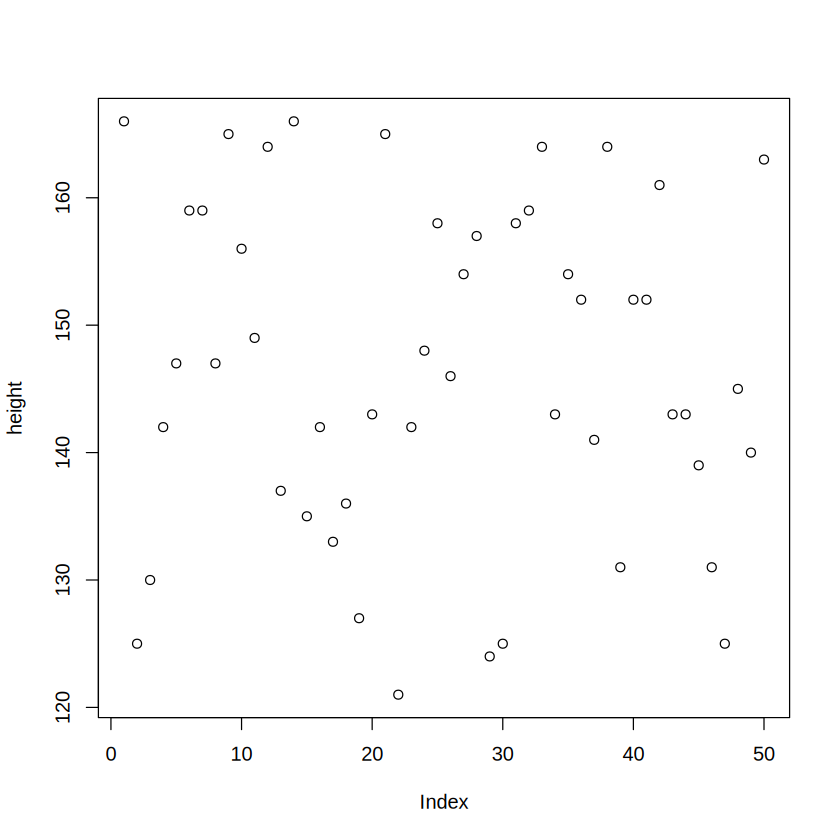

In [27]:
plot(height)


### Scatter plot with a title and axis labels

The NPTEL example primarily demonstrates `plot(height)`. We can also use standard `plot()` arguments to make the graph easier to interpret.


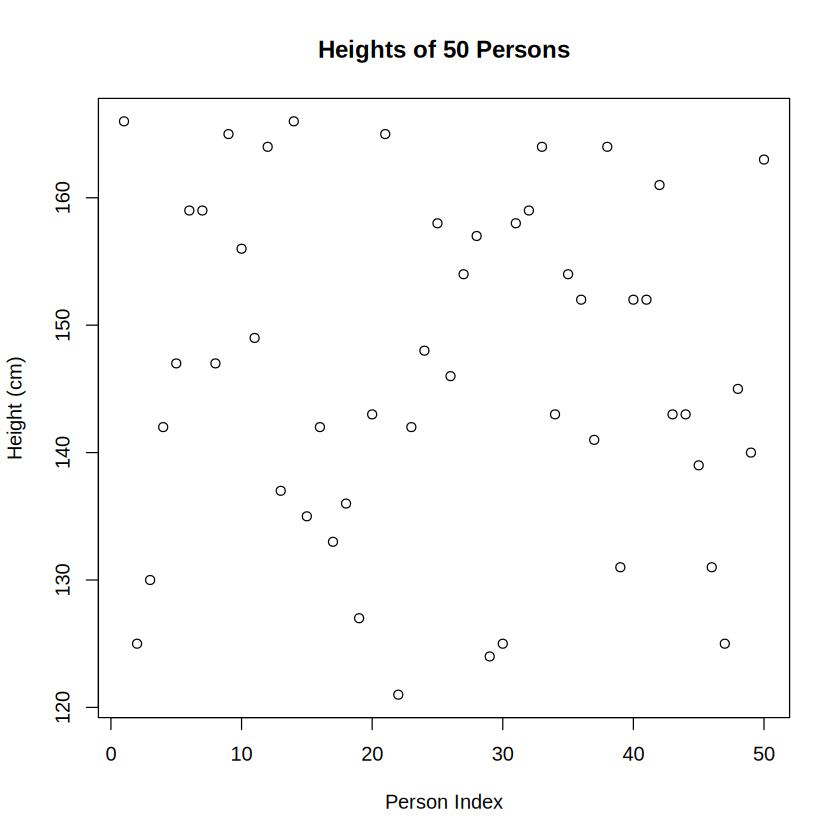

In [28]:
plot(
  height,
  main = "Heights of 50 Persons",
  xlab = "Person Index",
  ylab = "Height (cm)"
)


---
## 8. Bar Plots

Bar plots visualize the absolute or relative frequencies of observed values of a variable. The notes state that they are used for categorical variables and consist of one bar for each category.

Basic forms:

```r
barplot(table(x))                 # absolute frequencies
barplot(table(x)/length(x))      # relative frequencies
```


### Gender — absolute frequency


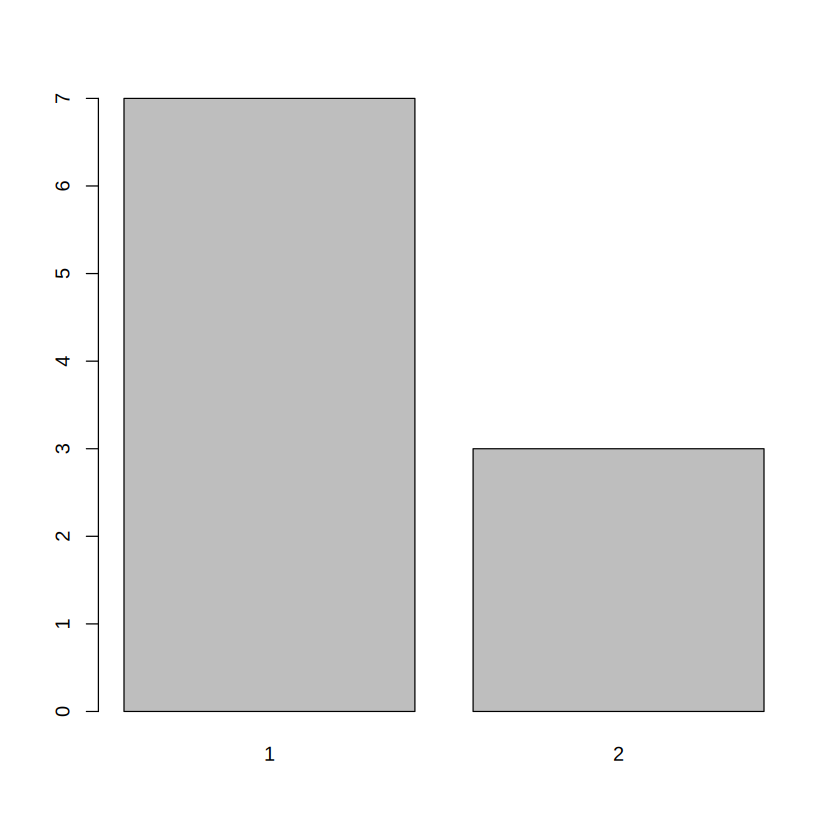

In [29]:
gender <- c(1, 2, 1, 2, 1, 1, 1, 2, 1, 1)

barplot(table(gender))


### Gender — relative frequency


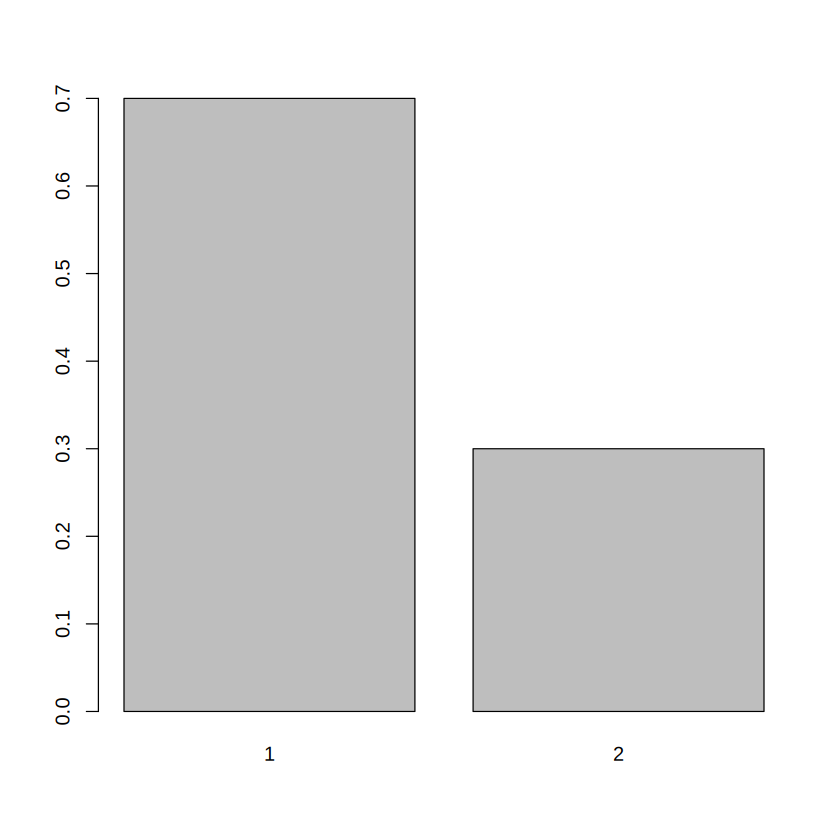

In [30]:
barplot(table(gender) / length(gender))


### Pizza delivery — absolute frequency


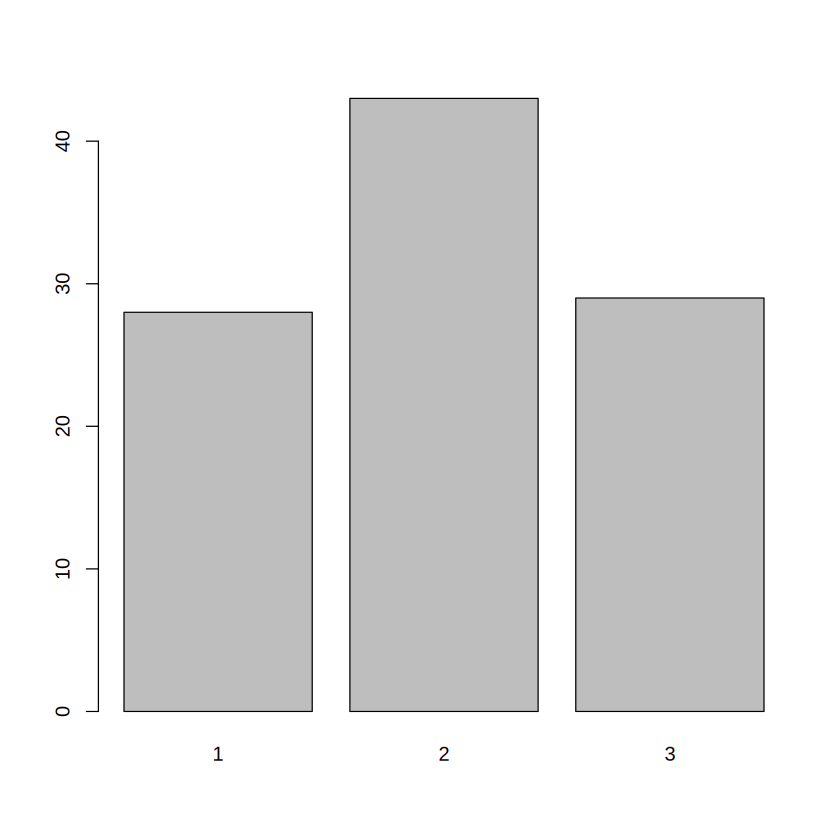

In [31]:
barplot(table(direction))


### Pizza delivery — relative frequency


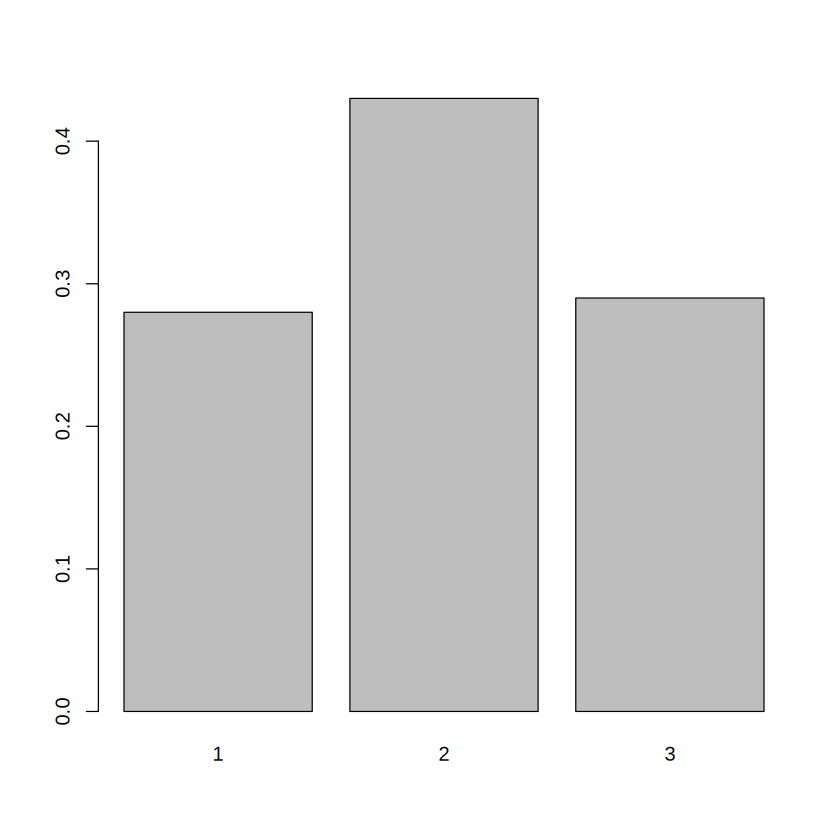

In [32]:
barplot(table(direction) / length(direction))


---
## 9. Customizing Bar Plots

The notes demonstrate progressively adding colours, a title, a legend, a subtitle, and axis labels.


### Adding colours


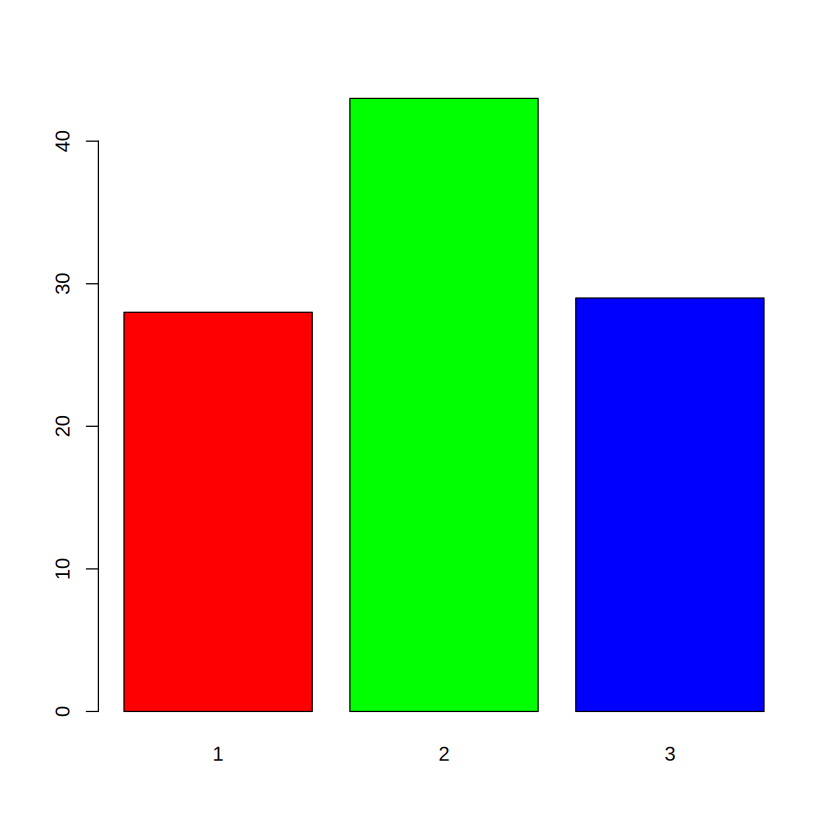

In [33]:
barplot(
  table(direction),
  col = c("red", "green", "blue")
)


### Adding a title


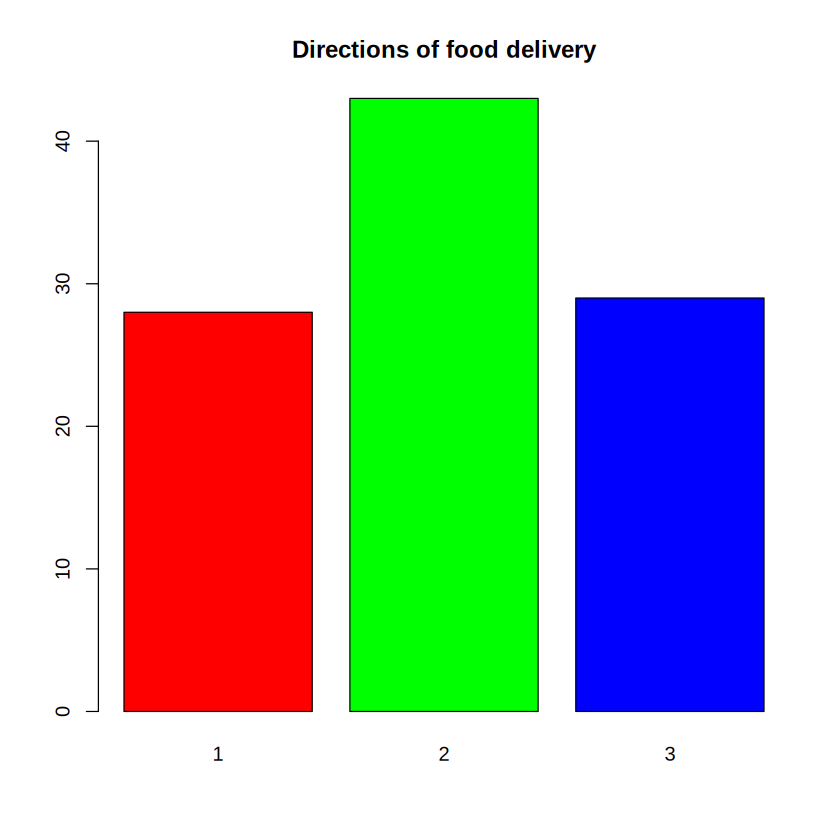

In [34]:
barplot(
  table(direction),
  col = c("red", "green", "blue"),
  main = "Directions of food delivery"
)


### Adding a legend


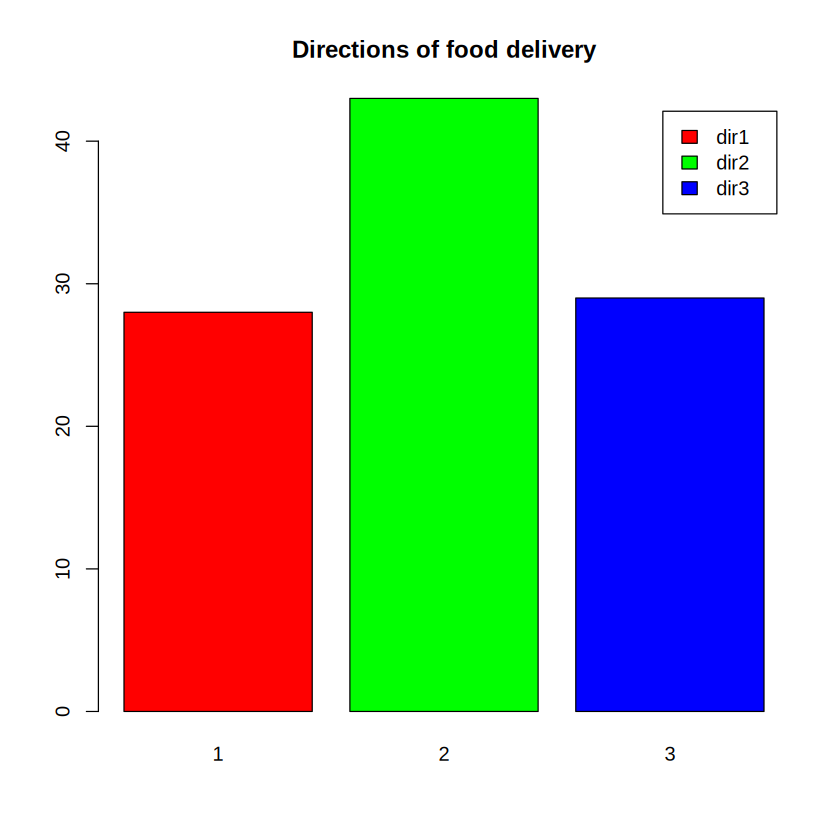

In [35]:
barplot(
  table(direction),
  col = c("red", "green", "blue"),
  main = "Directions of food delivery",
  legend.text = c("dir1", "dir2", "dir3")
)


### Adding a subtitle


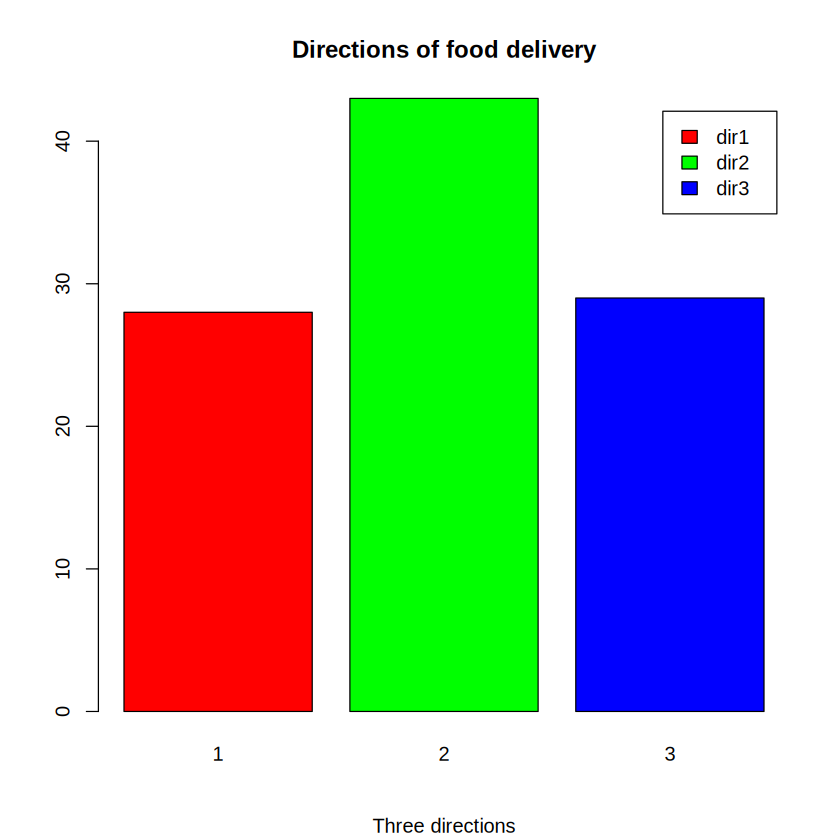

In [36]:
barplot(
  table(direction),
  col = c("red", "green", "blue"),
  main = "Directions of food delivery",
  legend.text = c("dir1", "dir2", "dir3"),
  sub = "Three directions"
)


### Adding x-axis and y-axis labels

This follows the final bar-plot example in the supplied notes.


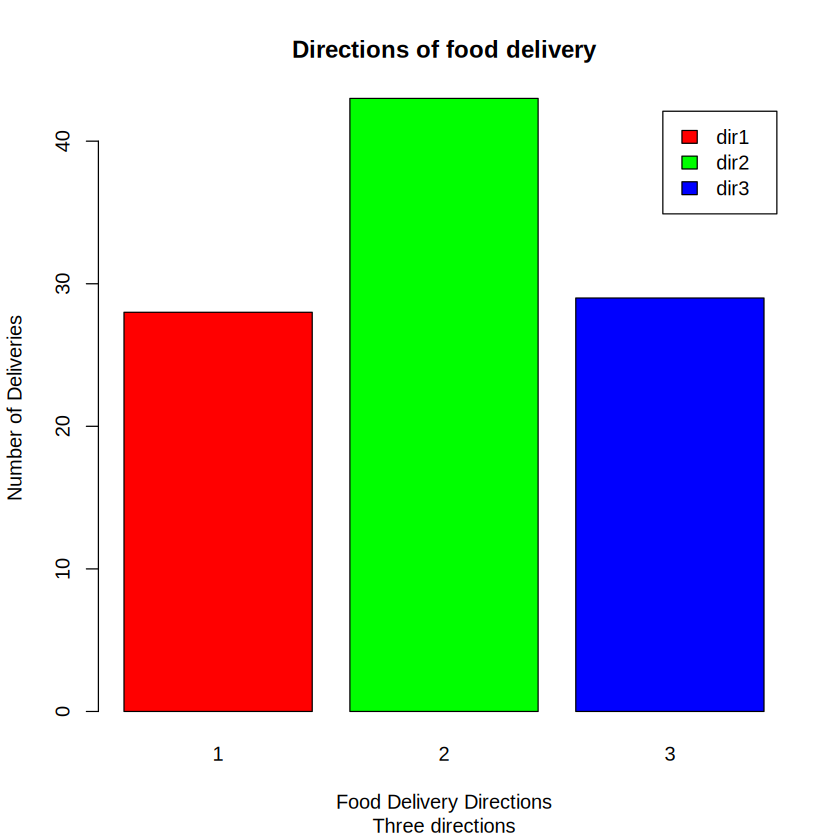

In [37]:
barplot(
  table(direction),
  col = c("red", "green", "blue"),
  main = "Directions of food delivery",
  legend.text = c("dir1", "dir2", "dir3"),
  sub = "Three directions",
  xlab = "Food Delivery Directions",
  ylab = "Number of Deliveries"
)


---
# 10. Practice Questions

## Q1. Excel data
Write R code to:
1. Load the `readxl` package.
2. Read the first sheet of `datafile.xlsx`.
3. Display the imported data.
4. Extract one variable.
5. Calculate its mean.

## Q2. Frequency
For the vector below, find the absolute and relative frequencies:

```r
x <- c(1,2,1,3,2,1,3,3,2,1,2,3)
```

## Q3. Quantiles
For the marks vector used above, calculate:
- minimum,
- 25th percentile,
- median,
- 75th percentile,
- maximum.

## Q4. Scatter plot
Create a scatter plot for `height` with:
- a title,
- x-axis label,
- y-axis label.

## Q5. Bar plot
For `direction`, create:
1. an absolute-frequency bar plot,
2. a relative-frequency bar plot,
3. a customized bar plot with colours, title, legend and axis labels.


x
1 2 3 
4 4 4 

x
        1         2         3 
0.3333333 0.3333333 0.3333333 

0%  25%  50%  75% 100% 
29.0 46.5 63.0 79.5 96.0

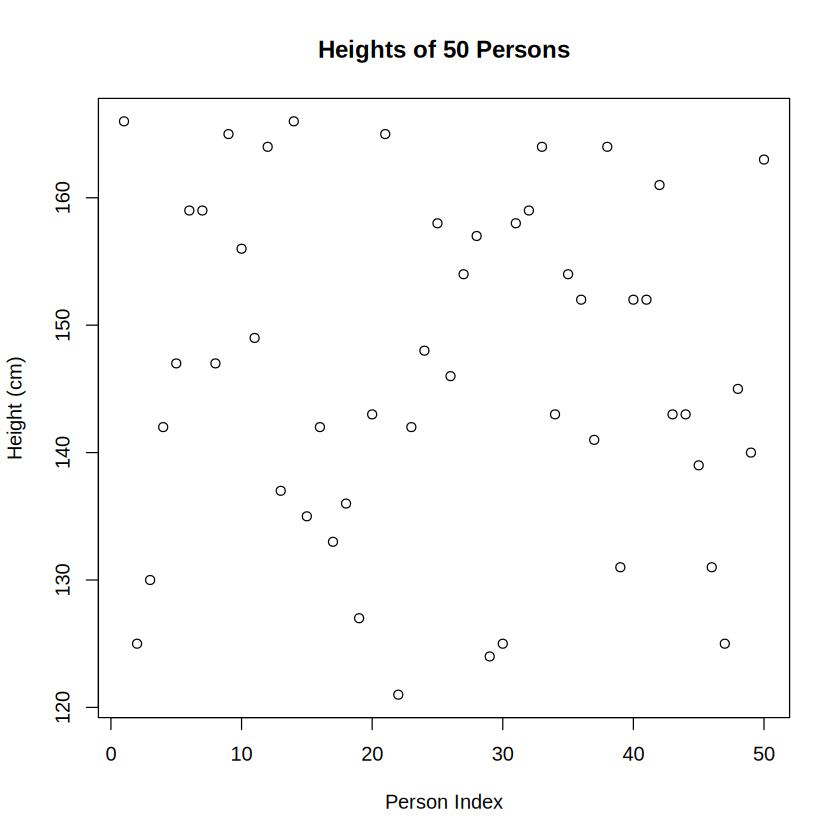

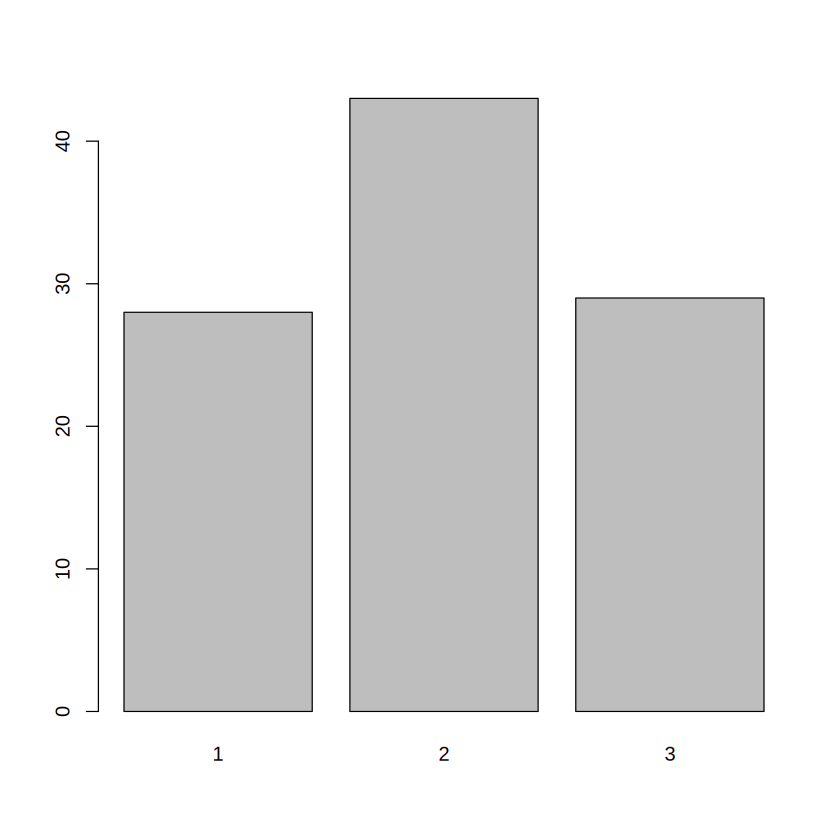

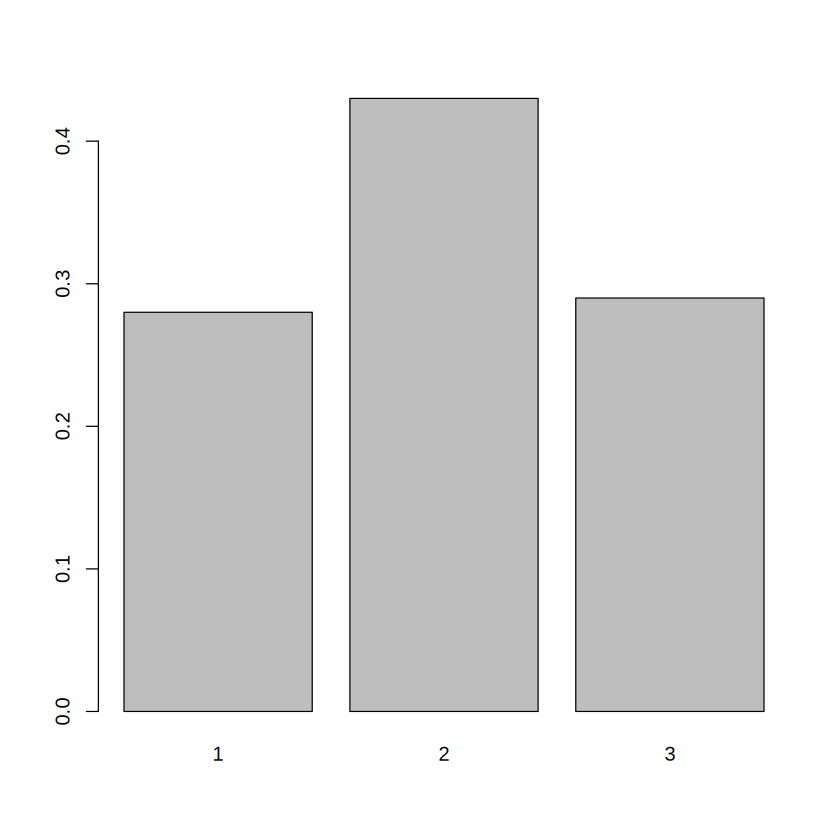

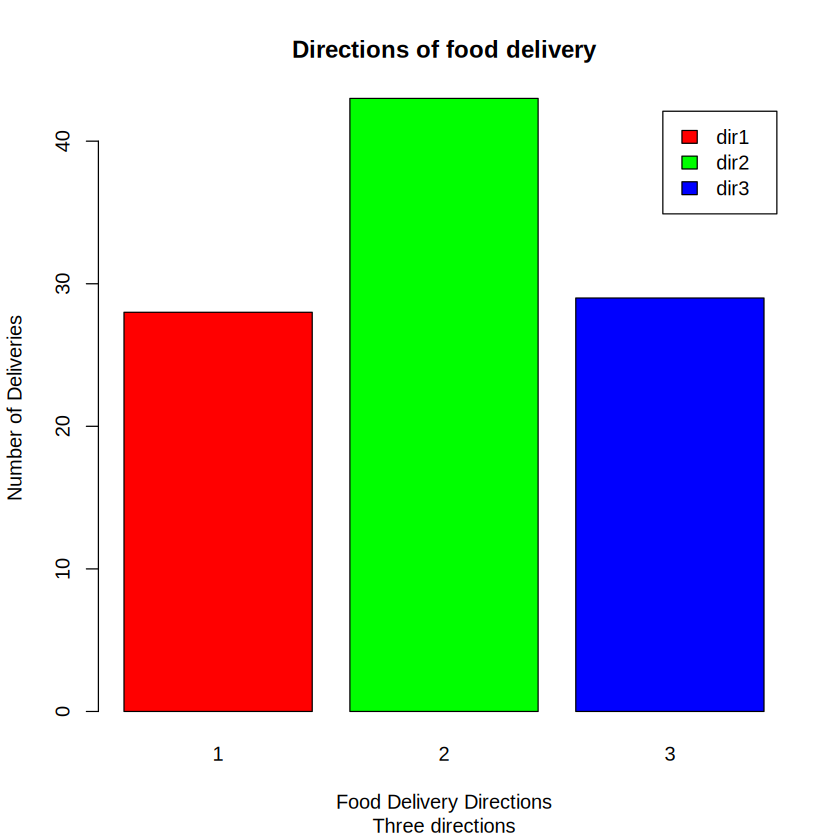

In [38]:
# Q1
# library(readxl)
# data <- read_excel("datafile.xlsx")
# data
# data$VariableName
# mean(data$VariableName)

# Q2
x <- c(1,2,1,3,2,1,3,3,2,1,2,3)
table(x)
table(x) / length(x)

# Q3
quantile(marks, probs = c(0, 0.25, 0.5, 0.75, 1))

# Q4
plot(
  height,
  main = "Heights of 50 Persons",
  xlab = "Person Index",
  ylab = "Height (cm)"
)

# Q5
barplot(table(direction))
barplot(table(direction) / length(direction))

barplot(
  table(direction),
  col = c("red", "green", "blue"),
  main = "Directions of food delivery",
  legend.text = c("dir1", "dir2", "dir3"),
  sub = "Three directions",
  xlab = "Food Delivery Directions",
  ylab = "Number of Deliveries"
)


---
# 11. Mini Practice Task

Use a small student dataset and complete the following:

1. Create a data frame containing student names, marks and gender.
2. Save it as a CSV file using `write.csv()`.
3. Calculate the frequency of each gender using `table()`.
4. Calculate relative frequencies.
5. Find the quartiles of marks using `quantile()`.
6. Draw a scatter plot of marks.
7. Draw a bar plot of gender.
8. Customize the bar plot with a title and axis labels.


In [39]:
students <- data.frame(
  Name = c("Aarav", "Diya", "Kabir", "Meera", "Riya", "Arjun"),
  Marks = c(72, 88, 65, 91, 79, 84),
  Gender = c("M", "F", "M", "F", "F", "M")
)

students


Name,Marks,Gender
<chr>,<dbl>,<chr>
Aarav,72,M
Diya,88,F
Kabir,65,M
Meera,91,F
Riya,79,F
Arjun,84,M



F M 
3 3 


  F   M 
0.5 0.5 

0%   25%   50%   75%  100% 
65.00 73.75 81.50 87.00 91.00

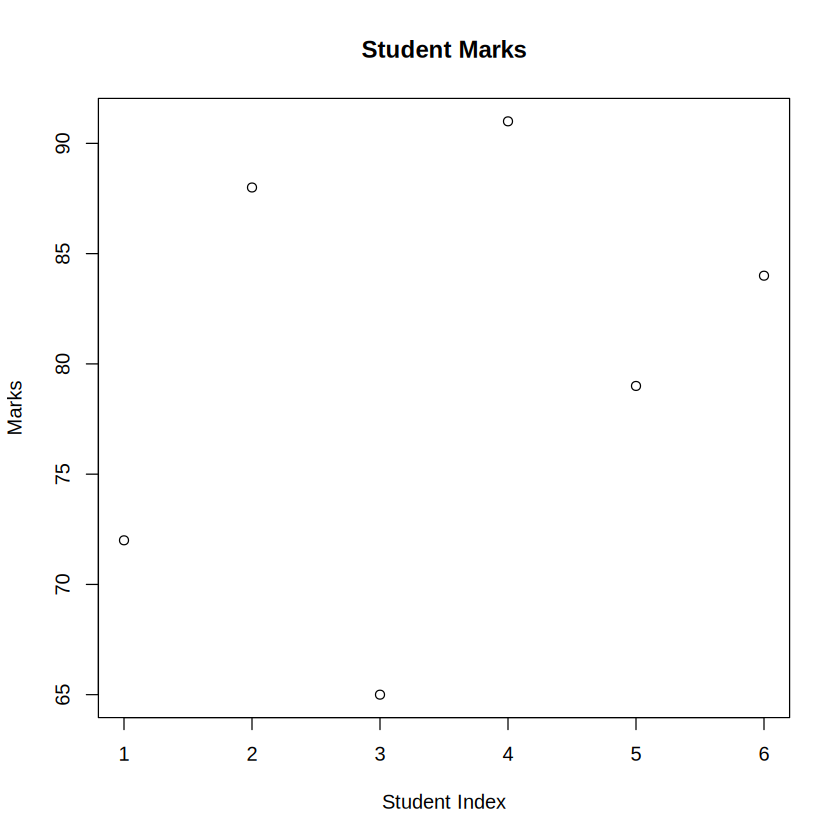

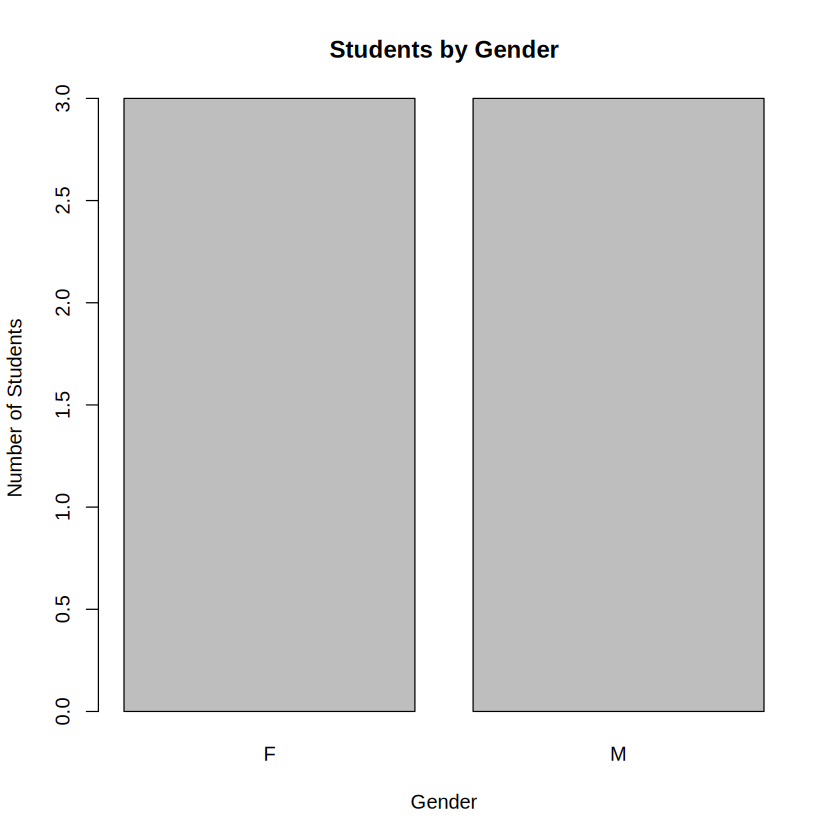

In [40]:
# Save the data
write.csv(students, "week11_students.csv", row.names = FALSE)

# Frequency
table(students$Gender)

# Relative frequency
table(students$Gender) / length(students$Gender)

# Quartiles
quantile(students$Marks)

# Scatter plot
plot(
  students$Marks,
  main = "Student Marks",
  xlab = "Student Index",
  ylab = "Marks"
)

# Bar plot
barplot(
  table(students$Gender),
  main = "Students by Gender",
  xlab = "Gender",
  ylab = "Number of Students"
)


---
# 12. Week 11 Summary

| Task | R command |
|---|---|
| Read Excel file | `read_excel()` |
| Select Excel sheet | `read_excel(..., sheet = ...)` |
| Limit Excel rows | `read_excel(..., n_max = ...)` |
| Read Excel range | `read_excel(..., range = ...)` |
| Read SPSS | `read.spss()` |
| Read HTML table | `readHTMLTable()` |
| Write data | `write()` |
| Write CSV | `write.csv()` |
| Write table | `write.table()` |
| Absolute frequency | `table(x)` |
| Relative frequency | `table(x)/length(x)` |
| Quantiles | `quantile(x)` |
| Scatter plot | `plot(x)` |
| Bar plot | `barplot(table(x))` |
| Relative-frequency bar plot | `barplot(table(x)/length(x))` |

## Completion checklist

- [ ] Excel import practiced
- [ ] Other file formats reviewed
- [ ] `write()` practiced
- [ ] `write.csv()` practiced
- [ ] `write.table()` practiced
- [ ] Absolute frequency practiced
- [ ] Relative frequency practiced
- [ ] `quantile()` practiced
- [ ] Scatter plot practiced
- [ ] Bar plot practiced
- [ ] Bar plot customization practiced
- [ ] Practice questions completed
